In [ ]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

# Path file sesuai dengan yang Anda miliki
file_path = '/content/drive/My Drive/ecomerce sales data/ecommerce_valid_revenue_data.csv'

# Membaca file CSV ke dalam DataFrame
df = pd.read_csv(file_path)

# Menampilkan 5 baris pertama dari data
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Order_ID,Order_Date,Product,Category,Quantity,Unit_Price,Discount,Region,Sales_Channel,Order_Status,Source_Row,Invalid_Quantity,Invalid_Unit_Price,Revenue
0,ORD-0001,2025-08-03,USB-C Hub,Accessories,6.0,34.50,0.05,East,Marketplace,Completed,0,False,False,196.6500
1,ORD-0002,2025-09-20,Desk Lamp,Home Office,2.0,24.99,0.10,South,Website,Completed,1,False,False,44.9820
2,ORD-0003,2025-10-27,Webcam HD,Electronics,4.0,49.99,0.00,South,Website,Completed,2,False,False,199.9600
3,ORD-0004,2025-01-22,Desk Organizer,Home Office,4.0,16.99,0.15,West,Social Media,Completed,3,False,False,57.7660
4,ORD-0005,2025-06-18,Wireless Mouse,Accessories,5.0,18.99,0.05,North,Social Media,Completed,4,False,False,90.2025


In [ ]:
# ==========================================
# 3. BUSINESS KPI SUMMARY
# ==========================================

total_revenue = df['Revenue'].sum()

total_orders = df['Order_ID'].nunique()

total_quantity = df['Quantity'].sum()

average_order_value = total_revenue / total_orders

print("===== E-COMMERCE BUSINESS KPI =====")

print("Total Revenue: £", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Quantity Sold:", total_quantity)
print("Average Revenue per Order: £",
      round(average_order_value, 2))

===== E-COMMERCE BUSINESS KPI =====
Total Revenue: £ 37207.55
Total Orders: 185
Total Quantity Sold: 648.0
Average Revenue per Order: £ 201.12


In [ ]:
# ==========================================
# 4. PRODUCT PERFORMANCE ANALYSIS
# ==========================================

product_performance = (
    df.groupby('Product', dropna=False)
    .agg(
        Total_Revenue=('Revenue', 'sum'),
        Total_Quantity=('Quantity', 'sum'),
        Total_Orders=('Order_ID', 'nunique')
    )
    .sort_values('Total_Revenue', ascending=False)
)

display(product_performance)

,Total_Revenue,Total_Quantity,Total_Orders
Product,,,
27-inch Monitor,14705.8500,70.0,20
Office Chair,7099.8500,51.0,16
USB-C Hub,3020.0500,94.0,25
Wireless Mouse,2416.3695,67.0,18
Webcam HD,2379.5240,49.0,12
Bluetooth Speaker,1975.5060,52.0,15
Mechanical Keyboard,1676.7205,29.0,10
Desk Organizer,974.3765,60.0,15
Laptop Stand,956.6810,34.0,11


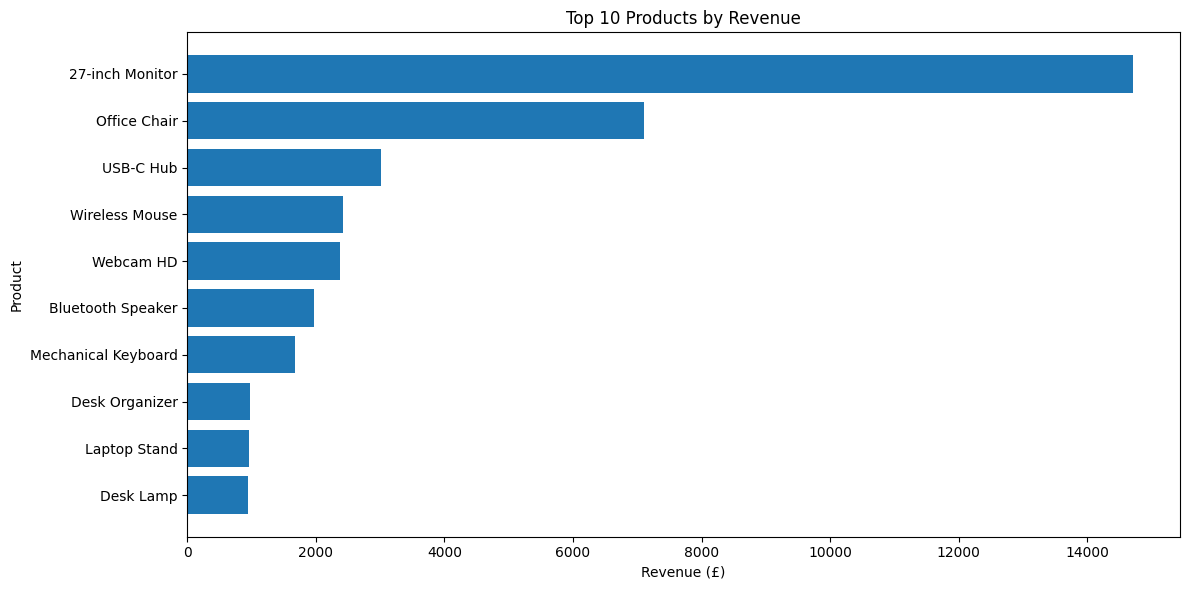

In [ ]:
# ==========================================
# 5. TOP 10 PRODUCTS BY REVENUE
# ==========================================

top_products = product_performance.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_products.index.astype(str),
    top_products['Total_Revenue']
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Product')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 6. REGIONAL PERFORMANCE ANALYSIS
# ==========================================

region_performance = (
    df.groupby('Region', dropna=False)
    .agg(
        Total_Revenue=('Revenue', 'sum'),
        Total_Orders=('Order_ID', 'nunique'),
        Total_Quantity=('Quantity', 'sum')
    )
    .sort_values('Total_Revenue', ascending=False)
)

display(region_performance)

,Total_Revenue,Total_Orders,Total_Quantity
Region,,,
West,13751.5635,59,205.0
South,11760.2695,43,143.0
East,6418.6885,42,138.0
North,5215.8680,40,158.0
NaN,61.1640,1,4.0


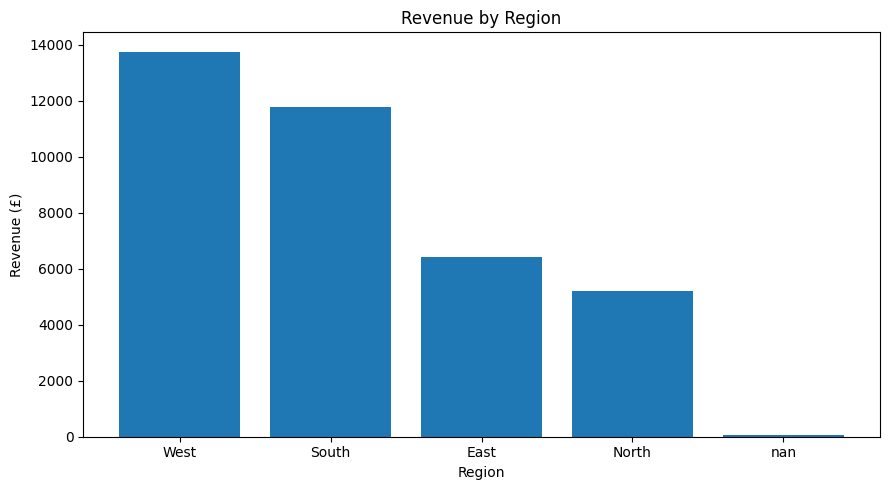

In [ ]:
# ==========================================
# 7. REVENUE BY REGION
# ==========================================

plt.figure(figsize=(9, 5))

plt.bar(
    region_performance.index.astype(str),
    region_performance['Total_Revenue']
)

plt.title('Revenue by Region')
plt.xlabel('Region')
plt.ylabel('Revenue (£)')

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 8. CATEGORY PERFORMANCE ANALYSIS
# ==========================================

category_performance = (
    df.groupby('Category', dropna=False)
    .agg(
        Total_Revenue=('Revenue', 'sum'),
        Total_Quantity=('Quantity', 'sum'),
        Total_Orders=('Order_ID', 'nunique')
    )
    .sort_values('Total_Revenue', ascending=False)
)

display(category_performance)

,Total_Revenue,Total_Quantity,Total_Orders
Category,,,
Electronics,20812.8800,179.0,49
Home Office,9026.3455,152.0,45
Accessories,6738.9010,216.0,63
Stationery,629.4270,101.0,28


In [ ]:
# ==========================================
# 9. MONTHLY REVENUE ANALYSIS
# ==========================================

df['Order_Date'] = pd.to_datetime(
    df['Order_Date'],
    errors='coerce'
)

# Baris tanpa tanggal tidak dapat dimasukkan
# ke analisis tren waktu
df_dated = df.dropna(subset=['Order_Date']).copy()

df_dated['Month'] = (
    df_dated['Order_Date'].dt.to_period('M')
)

monthly_revenue = (
    df_dated.groupby('Month')['Revenue']
    .sum()
    .reset_index()
)

monthly_revenue['Month'] = (
    monthly_revenue['Month'].astype(str)
)

display(monthly_revenue)

,Month,Revenue
0,2025-01,2527.7155
1,2025-02,3377.9840
2,2025-03,3975.0510
3,2025-04,3047.3755
4,2025-05,2935.0965
5,2025-06,2994.6710
6,2025-07,5341.8095
7,2025-08,5269.7810
8,2025-09,3065.2200
9,2025-10,4672.8495


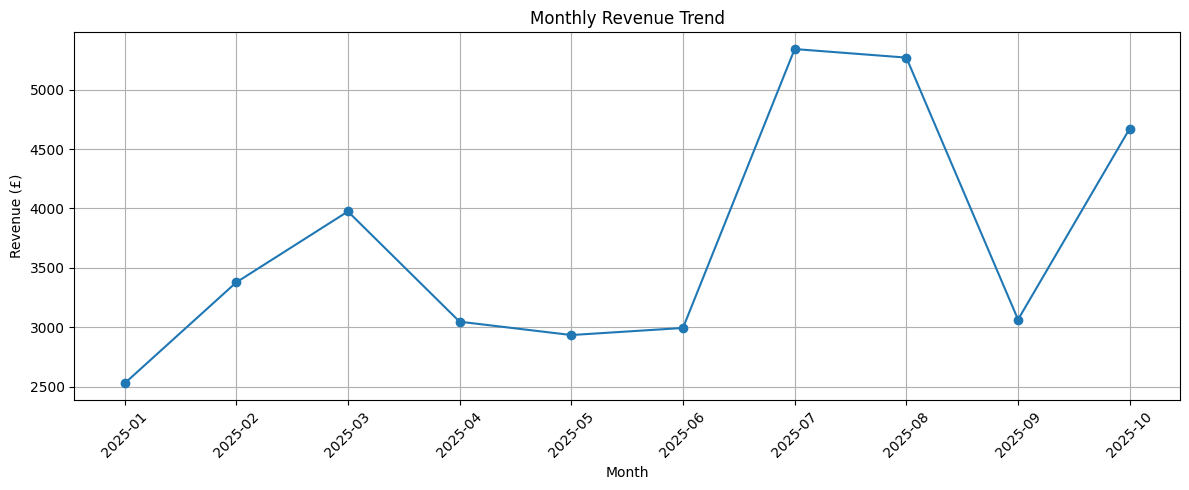

In [ ]:
# ==========================================
# 10. MONTHLY REVENUE TREND
# ==========================================

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue['Month'],
    monthly_revenue['Revenue'],
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 11. SALES CHANNEL ANALYSIS
# ==========================================

channel_performance = (
    df.groupby('Sales_Channel', dropna=False)
    .agg(
        Total_Revenue=('Revenue', 'sum'),
        Total_Orders=('Order_ID', 'nunique')
    )
    .sort_values('Total_Revenue', ascending=False)
)

display(channel_performance)

,Total_Revenue,Total_Orders
Sales_Channel,,
Social Media,15463.2665,65
Marketplace,11004.0350,55
Website,10654.7970,64
NaN,85.4550,1


In [ ]:
# ==========================================
# 12. HANDLE MISSING CATEGORY LABELS
# ==========================================

df['Product'] = df['Product'].fillna('Unknown')
df['Region'] = df['Region'].fillna('Unknown')
df['Sales_Channel'] = df['Sales_Channel'].fillna('Unknown')

# Verifikasi
print("Missing Product:", df['Product'].isna().sum())
print("Missing Region:", df['Region'].isna().sum())
print("Missing Sales Channel:", df['Sales_Channel'].isna().sum())

Missing Product: 0
Missing Region: 0
Missing Sales Channel: 0
